# Session 14: Unsupervised Learning

**Learning goals:**

- Distinguish supervised learning from unsupervised learning.
- Scale numeric features for distance-based analysis.
- Use principal component analysis (PCA) and interpret explained variance.
- Standardise features with StandardScaler, then fit K-Means.
- Compare cluster counts using the elbow method and internal metrics.
- Evaluate cluster separation and sizes, and explain limitations.

**Prerequisites:**

- Session 13 machine learning workflows, pandas DataFrames, NumPy arrays, and basic Matplotlib plotting.


## Outline

1. Supervised learning versus unsupervised learning
2. PCA and explained variance with the Wine dataset
3. K-Means clustering with StandardScaler
4. K-Means evaluation: the elbow method and internal metrics
5. Other clustering methods: DBSCAN


## 1. Supervised Learning versus Unsupervised Learning

Supervised and unsupervised learning are two machine learning approaches. The key difference is whether the training data includes a known target variable.

![Supervised learning uses features and known labels; unsupervised learning uses features only to discover structure.](images/supervised-vs-unsupervised.png)

| Learning type | Input | Output | Typical question |
|---|---|---|---|
| Supervised learning | Features `X` and target `y` | Prediction for `y` | Can we predict house price, species, churn, or pass/fail? |
| Unsupervised learning | Features `X` only | Components or clusters | Which observations are similar, and what hidden groups exist? |



## 2. Principal Component Analysis

**Principle:** PCA rotates the feature space to find directions that capture the most variation. The first principal component captures the largest amount of variation, the second captures the next largest amount while remaining perpendicular to the first, and so on.

[Watch: PCA video](https://www.youtube.com/shorts/3YT17tXjzWI)

PCA is often used before visualisation because it can compress several numeric features into two dimensions.

![PCA principle](images/pca-principle.png)


### 2.1 Load the Wine Dataset

Use scikit-learn's built-in Wine dataset: 178 wine samples with 13 numeric chemical measurements, including alcohol, malic acid, colour intensity and proline. It is bundled with scikit-learn, so no CSV or download is required.

`wine_data.data` contains only features. We exclude `wine_data.target` (the three known cultivar classes) from fitting: unsupervised methods discover structure from `X` alone. Section 4.3 uses these labels only for a final comparison after clustering.


In [40]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine

RANDOM_STATE = 42


# Load the numeric feature table only; do not use the known cultivar labels.
wine_data = load_wine(as_frame=True)
X_wine = wine_data.data.copy()
wine = X_wine.copy()

print(f"{X_wine.shape[0]} wine samples, {X_wine.shape[1]} numeric features")
display(X_wine.head())


178 wine samples, 13 numeric features


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 2.2 PCA Implementation and Results

Standardise the 13 numeric features with `StandardScaler`, then apply `PCA(n_components=2)` to obtain two principal components.

The code below produces:

- `wine_pca`: each sample's coordinates on PC1 and PC2 for plotting.
- `pca_result`: the explained variance ratio, percentage and cumulative percentage for the two components.

Only feature values are used; the known cultivar labels are excluded.


In [41]:
# Import scaling and PCA for the dimension reduction step.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardise features so PCA is not dominated by variables with larger numeric scales.
scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)

# Reduce the 13 wine features to two principal components for plotting.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
wine_pca_array = pca.fit_transform(X_wine_scaled)

# Store the PCA result in a DataFrame for easier plotting and joining with cluster labels later.
wine_pca = pd.DataFrame(wine_pca_array, columns=["PC1", "PC2"])

# Show each component's share of total variance and the cumulative share.
pca_result = pd.DataFrame(
    {
        "Principal component": ["PC1", "PC2"],
        "Explained variance ratio": pca.explained_variance_ratio_,
        "Explained variance percentage": pca.explained_variance_ratio_ * 100,
        "Cumulative percentage": pca.explained_variance_ratio_.cumsum() * 100,
    }
)

pca_result

,Principal component,Explained variance ratio,Explained variance percentage,Cumulative percentage
0,PC1,0.361988,36.198848,36.198848
1,PC2,0.192075,19.207490,55.406338


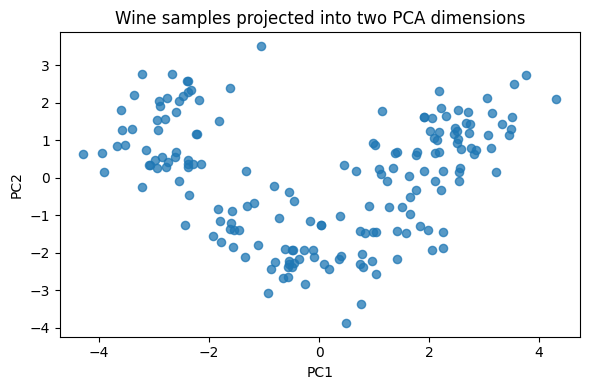

In [42]:
# Plot wine samples in the two-dimensional PCA space.
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(wine_pca["PC1"], wine_pca["PC2"], alpha=0.75, s=35)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Wine samples projected into two PCA dimensions")
fig.tight_layout()
plt.show()

## 3. K-Means Clustering

**Principle:** clustering looks for groups of similar observations without using a known target label. K-Means is one common clustering method. It groups observations around `k` centroids.

[Watch: K-Means video](https://www.youtube.com/watch?v=4b5d3muPQmA&t)

Each point is assigned to the nearest centroid, then the centroids move to the centre of their assigned points. This repeats until the cluster assignments stabilise.

![K-Means principle](images/kmeans-principle.png)


### 3.1 K-Means Workflow

![Raw features become scaled features using StandardScaler().fit_transform(raw_features), then cluster labels using KMeans(n_clusters=k).fit_predict(scaled_features).](images/kmeans-workflow.png)

K-Means depends on distances, so scaling matters. Apply the two steps explicitly:

1. Use `StandardScaler.fit_transform(X_wine)` to standardise the 13 numeric features.
2. Pass the scaled features to `KMeans.fit_predict()` to assign each sample to a cluster.

The first code cell scales the features; the next fits K-Means. Reuse the same scaled features for the elbow method and internal evaluation. PCA provides the plotting coordinates only.


In [43]:
from sklearn.preprocessing import StandardScaler

# Step 1: standardise the original features before calculating distances.
kmeans_scaler = StandardScaler()
X_wine_scaled_for_kmeans = kmeans_scaler.fit_transform(X_wine)


### 3.2 K-Means Parameters

The model below uses `KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)`.

| Parameter | Value in this lesson | Meaning |
|---|---|---|
| `n_clusters` | `3` | Form three clusters, each with its own centroid. Choose this value before fitting; Section 4 compares possible choices. |
| `random_state` | `RANDOM_STATE` (`42`) | Fix the random seed for centroid initialisation so repeated runs with the same data and settings are reproducible. It does not determine the number of clusters. |
| `n_init` | `10` | Run K-Means ten times with different initial centroids, then keep the result with the lowest inertia. This helps reduce sensitivity to initialisation. |

Other useful parameters include `init` (how initial centroids are chosen), `max_iter` (the maximum number of assignment/update iterations in each run), and `tol` (the tolerance for declaring convergence).

`n_init` counts separate runs; `max_iter` limits iterations within each run. Cluster labels such as `0`, `1` and `2` identify groups and have no ranking.


In [44]:
from sklearn.cluster import KMeans

# Fit K-Means on the standardised features.
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_wine_scaled_for_kmeans)

# Attach cluster labels to the original data and the PCA plotting table.
wine["kmeans_cluster"] = kmeans_labels
wine_pca["kmeans_cluster"] = kmeans_labels

# Count wine samples in each cluster.
wine["kmeans_cluster"].value_counts().sort_index()


kmeans_cluster
0    65
1    51
2    62
Name: count, dtype: int64

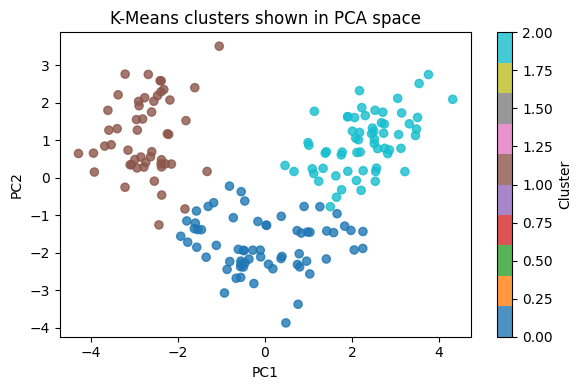

In [45]:
# Plot K-Means clusters in PCA space.
fig, ax = plt.subplots(figsize=(6, 4))
scatter = ax.scatter(
    wine_pca["PC1"],
    wine_pca["PC2"],
    c=wine_pca["kmeans_cluster"],
    cmap="tab10",
    alpha=0.8,
    s=35,
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("K-Means clusters shown in PCA space")
plt.colorbar(scatter, ax=ax, label="Cluster")
fig.tight_layout()
plt.show()

## 4. K-Means Evaluation

Use the elbow method to compare candidate cluster counts, then evaluate cluster compactness, separation and sizes. All calculations use the same standardised original features used to fit K-Means.


### 4.1 Elbow Method for Choosing `k`

K-Means needs the number of clusters, `k`, before fitting. The **elbow method** tries several `k` values and records inertia.

Inertia is the sum of squared distances from each point to its assigned centroid. Lower inertia means tighter clusters, but inertia always decreases as `k` increases. The goal is to look for an **elbow**, where adding more clusters gives only a small improvement.


In [46]:
# Try several k values using the same standardised feature table.
k_values = range(1, 11)
elbow_rows = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_wine_scaled_for_kmeans)
    elbow_rows.append(
        {
            "k": k,
            "inertia": model.inertia_,
        }
    )

elbow_results = pd.DataFrame(elbow_rows)
elbow_results


,k,inertia
0,1,2314.000000
1,2,1658.758852
2,3,1277.928489
3,4,1175.428333
4,5,1109.512739
5,6,1046.002333
6,7,981.595233
7,8,935.201211
8,9,889.892911
9,10,845.895237


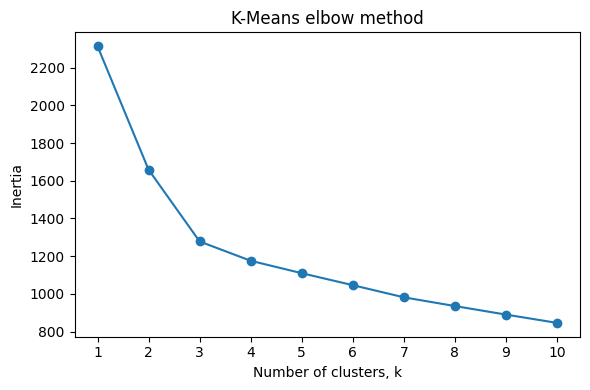

In [47]:
# Plot the elbow curve.
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(elbow_results["k"], elbow_results["inertia"], marker="o")
ax.set_xlabel("Number of clusters, k")
ax.set_ylabel("Inertia")
ax.set_title("K-Means elbow method")
ax.set_xticks(list(k_values))
fig.tight_layout()
plt.show()

In this notebook, we continue with `k = 3` as an initial teaching choice. The elbow method is a guide, so also consider silhouette score, cluster sizes and the chemical profiles of the groups.

Do not choose `k` solely because the dataset has three known cultivars. Those labels are excluded from fitting and evaluation here. Compare candidate cluster counts using the feature values.


### 4.2 Internal Clustering Metrics

These **internal evaluation metrics** do not use the supplied cultivar labels. These metrics judge compactness and separation using the feature values and cluster labels.

| Metric | Meaning | How to judge |
|---|---|---|
| Silhouette score | Compares how close each point is to its own cluster versus the nearest other cluster. | Higher is better. Values are usually between -1 and 1. |
| Davies-Bouldin score | Compares within-cluster spread with between-cluster separation. | Lower is better. |
| Calinski-Harabasz score | Compares between-cluster dispersion with within-cluster dispersion. | Higher is better. |


In [48]:
# Import clustering evaluation metrics.
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

# Calculate several internal clustering evaluation metrics.
clustering_evaluation = pd.DataFrame(
    {
        "Metric": [
            "Silhouette score",
            "Davies-Bouldin score",
            "Calinski-Harabasz score",
        ],
        "Value": [
            silhouette_score(X_wine_scaled_for_kmeans, kmeans_labels),
            davies_bouldin_score(X_wine_scaled_for_kmeans, kmeans_labels),
            calinski_harabasz_score(X_wine_scaled_for_kmeans, kmeans_labels),
        ],
        "Preferred direction": ["Higher", "Lower", "Higher"],
    }
)

clustering_evaluation

,Metric,Value,Preferred direction
0,Silhouette score,0.284859,Higher
1,Davies-Bouldin score,1.389188,Lower
2,Calinski-Harabasz score,70.940008,Higher


### 4.3 Compare Clusters with Known Labels

Use a cross-tabulation to count samples for each true-label / cluster pair. Cluster IDs are arbitrary and do not need to match the true label numbers.


In [49]:
pd.crosstab(
    wine_data.target.rename("True label"),
    pd.Series(kmeans_labels, index=X_wine.index, name="K-Means cluster"),
)


K-Means cluster,0,1,2
True label,,,
0,0,0,59
1,65,3,3
2,0,48,0


## 5. Other Clustering Methods

K-Means is one option. Other methods include **agglomerative clustering**, which builds a hierarchy by merging groups, and **DBSCAN**, which finds groups using local density.

Explore the [scikit-learn clustering overview](https://scikit-learn.org/stable/modules/clustering.html) for a comparison of available methods.


### 5.1 DBSCAN

**DBSCAN** stands for *Density-Based Spatial Clustering of Applications with Noise*. It connects dense regions into clusters and marks isolated observations as noise.

- **No preset cluster count:** unlike K-Means, DBSCAN does not require `n_clusters`.
- **Flexible shapes:** it can find curved or irregular groups.
- **Noise:** scikit-learn assigns noise points the label `-1`.

[Watch: DBSCAN video](https://www.youtube.com/watch?v=RDZUdRSDOok)

![K-Means groups around centroids; DBSCAN follows dense curved regions and marks isolated points as noise.](images/kmeans-vs-dbscan.png)



[Read: scikit-learn DBSCAN guide](https://scikit-learn.org/stable/modules/clustering.html#dbscan)
